<table style="border:0;width:100%;border-collapse:collapse"><tr style="border:0"><td style="border:0;width:105px;vertical-align:middle"><img src="../Imagenes/logo-final-ap.png" width="90"/></td><td style="border:0;vertical-align:middle"><span style="font-size:32px;font-weight:700;color:#bd232b">Aprendizaje Profundo</span></td></tr></table>

[https://github.com/AprendizajeProfundo](https://github.com/AprendizajeProfundo)

# <span style="color:#174ea6">Cuaderno 107 · Meta-learning y adaptación rápida a nuevas condiciones operativas</span>

**Sesión 4 · Primera lección · 55 minutos en clase (ampliaciones para estudio autónomo)**

**Autores:** Alvaro Montenegro · Daniel Montenegro · Pilar Montenegro  
**Docente:** Alvaro Montenegro, [ammontenegrod@gmail.com](mailto:ammontenegrod@gmail.com),    
**Institución:** Universidad de los Andes - Ecopetrol  
**Edición docente:** 107 · Octubre de 2026  
**Licencia del contenido y código originales de esta edición:** MIT (véase sección final).

> **Pregunta rectora.** ¿Cómo preparar un modelo para que aprenda rápidamente una tarea nueva, sin confundir adaptación genuina con haber visto antes esa tarea?

**Fuentes directas:** programa aprobado de la sesión 4; cuadernos 103 y 104 (gradientes, entrenamiento y evaluación); documentación conceptual de Hydro-Lab S2.11 y arquitectura G2.4. El experimento es **sintético** y no representa resultados medidos en Hydro-Lab.


# <span style="color:#174ea6">Contenido y ruta de clase</span>

**0–15 min:** distribución de tareas y cambios operativos. **15–35 min:** transferencia, fine-tuning y meta-learning; Reptile. **35–55 min:** ejecutar adaptación en tareas disjuntas, interpretar curvas y discutir su transferencia a Hydro-Lab.

1. El problema de aprender a adaptarse. 2. Formulación matemática. 3. Reptile de primer orden. 4. Experimento reproducible. 5. Evaluación honesta y límites. 6. Conexión con Hydro-Lab. 7. Actividades y referencias.

**Requisitos:** Python, NumPy, Matplotlib y PyTorch. No se requiere Gymnasium ni ejecutar Hydro-Lab. El entrenamiento está deliberadamente reducido para una clase de 55 minutos.

# <span style="color:#174ea6">1. Aprender una tarea no equivale a aprender a adaptarse</span>

<img src="../Imagenes/arquitectura_laboratorio_G2.4.png" width="1050"/>

En una red de transporte de hidrocarburos pueden cambiar la **demanda**, la **viscosidad**, la **capacidad disponible** y las **condiciones de operación**. El controlador debe mantener las restricciones físicas y responder a esos cambios. Es distinto entrenar una política para un escenario fijo que diseñar una inicialización capaz de adaptarse con pocos datos a escenarios nuevos.

Usaremos tres ideas:

- **Entrenamiento desde cero:** inicialización no informada, seguida de adaptación a la tarea.
- **Transferencia / fine-tuning:** parámetros aprendidos en una tarea fuente y ajustados a otra.
- **Meta-learning:** entrenamiento a través de muchas tareas, buscando que los *pasos de adaptación* funcionen bien en tareas futuras.

Una cuarta referencia importante es el **preentrenamiento conjunto (pooled)**: optimizar una sola red con ejemplos de todas las tareas de entrenamiento. Es una línea base más exigente que entrenar en una única tarea.

## <span style="color:#bd232b">1.1 Qué es una tarea</span>

Representamos una tarea por $\tau\sim p(\mathcal T)$, donde $\tau$ determina las condiciones de generación de datos y su función de pérdida $\mathcal L_\tau(\theta)$. En un sistema hidráulico una tarea podría incluir parámetros de demanda, propiedades del fluido y equipos disponibles.

**Distinción crucial:** la distribución de entrenamiento $p_{\mathrm{train}}(\mathcal T)$ no es el conjunto de tareas de prueba. Las tareas de prueba deben ser **identidades nuevas** y sus muestras de evaluación no pueden usarse para adaptar el modelo.

En el laboratorio reduciremos la complejidad a regresiones sinusoidales:

$$y_\tau(x)=A_\tau\sin(x+\varphi_\tau)+\varepsilon,\qquad \varepsilon\sim\mathcal N(0,\sigma^2).$$

Cada par $(A_\tau,\varphi_\tau)$ define una tarea diferente. Este problema no simula dinámica hidráulica; **ilustra únicamente la adaptación entre tareas**.

# <span style="color:#174ea6">2. Formulación matemática: aprendizaje interno y externo</span>

## <span style="color:#bd232b">2.1 Adaptación a una tarea</span>

Con parámetros iniciales $\theta$ y conjunto de soporte $D_\tau^{\mathrm{sup}}$, una actualización de descenso de gradiente es

$$\theta_\tau^{(k+1)}=\theta_\tau^{(k)}-\alpha\nabla_\theta\mathcal L_\tau\!\left(\theta_\tau^{(k)};D_\tau^{\mathrm{sup}}\right),\quad \theta_\tau^{(0)}=\theta.$$

Después de $K$ pasos obtenemos $U_\tau^K(\theta)$. El desempeño debe medirse sobre un **conjunto de consulta** $D_\tau^{\mathrm{qry}}$ que no intervino en la adaptación:

$$J(\theta)=\mathbb E_{\tau\sim p(\mathcal T)}\left[\mathcal L_\tau\big(U_\tau^K(\theta);D_\tau^{\mathrm{qry}}\big)\right].$$

Esta es la perspectiva *bilevel*: un aprendizaje interno por tarea y otro externo entre tareas. Minimizar la pérdida de entrenamiento de la tarea no basta para demostrar capacidad de generalización.

## <span style="color:#bd232b">2.2 MAML y aproximaciones de primer orden</span>

**MAML** diferencia a través de los pasos internos y, por tanto, puede involucrar derivadas de segundo orden. **First-order MAML (FOMAML)** omite esas derivadas. **Reptile** emplea un desplazamiento de parámetros y tampoco requiere diferenciación de segundo orden.

No son algoritmos idénticos. En particular, Reptile no evalúa explícitamente el gradiente de una pérdida de consulta en cada iteración externa: aproxima un sesgo de inicialización útil para el aprendizaje dentro de las tareas.

Para $K$ pasos internos sobre la tarea $\tau$, Reptile aplica

$$\boxed{\theta\leftarrow\theta+\epsilon\left(U_\tau^K(\theta)-\theta\right).}$$

Al promediar desplazamientos de varias tareas se reduce la variabilidad de la actualización. El tamaño $\epsilon$ regula la velocidad del aprendizaje externo; $\alpha$ controla la adaptación interna.

# <span style="color:#174ea6">3. Algoritmo Reptile: una implementación que podemos inspeccionar</span>

El siguiente código utiliza una red pequeña en PyTorch y no depende de bibliotecas especializadas de meta-learning. Cada tarea se genera con una semilla independiente; durante el metaentrenamiento se toman ejemplos nuevos y se ejecutan varios pasos de adaptación.

**Advertencia metodológica:** una inicialización obtenida con Reptile no garantiza superar siempre al entrenamiento conjunto. El objetivo de este experimento es **medir** la diferencia, no asumirla.

In [1]:
import copy
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn

SEED = 107
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
DEVICE = torch.device('cpu')
print('PyTorch:', torch.__version__, '| dispositivo:', DEVICE)


PyTorch: 2.14.1 | dispositivo: cpu


## <span style="color:#bd232b">3.1 Distribución de tareas y conjuntos disjuntos</span>

In [2]:
def sample_task(rng):
    """Una tarea sinusoidal queda fijada por amplitud y fase."""
    return (float(rng.uniform(0.5, 2.0)), float(rng.uniform(-np.pi, np.pi)))

def sample_data(task, n, rng, noise=0.05):
    amp, phase = task
    x = rng.uniform(-5.0, 5.0, size=(n, 1)).astype('float32')
    y = (amp * np.sin(x + phase) + rng.normal(0, noise, size=(n, 1))).astype('float32')
    return torch.from_numpy(x), torch.from_numpy(y)

rng_train = np.random.default_rng(SEED)
rng_test = np.random.default_rng(SEED + 10000)
train_tasks = [sample_task(rng_train) for _ in range(160)]
test_tasks = [sample_task(rng_test) for _ in range(24)]
assert len(set(train_tasks).intersection(set(test_tasks))) == 0
print('Tareas entrenamiento:', len(train_tasks), '| tareas prueba:', len(test_tasks))


Tareas entrenamiento: 160 | tareas prueba: 24


## <span style="color:#bd232b">3.2 Modelo, pérdida y adaptación</span>

In [3]:
def make_model(seed=SEED):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(1, 32), nn.Tanh(), nn.Linear(32, 32), nn.Tanh(), nn.Linear(32, 1))

def mse(model, data):
    x, y = data
    return torch.mean((model(x) - y) ** 2)

def adapt(model, support, steps, lr=0.01):
    """Adapta una copia: jamás altera los parámetros de la inicialización."""
    local = copy.deepcopy(model)
    optimizer = torch.optim.SGD(local.parameters(), lr=lr)
    for _ in range(steps):
        optimizer.zero_grad()
        loss = mse(local, support)
        loss.backward()
        optimizer.step()
    return local

probe = make_model()
support_probe = sample_data(train_tasks[0], 10, rng_train)
assert np.isfinite(mse(adapt(probe, support_probe, 2), support_probe).item())


## <span style="color:#bd232b">3.3 Metaentrenamiento: Reptile</span>

In [4]:
def train_reptile(tasks, iterations=120, batch_tasks=4, inner_steps=5,
                  inner_lr=0.01, outer_lr=0.15, n_support=10, seed=SEED):
    rng = np.random.default_rng(seed)
    meta = make_model(seed)
    history = []
    for it in range(iterations):
        base = [p.detach().clone() for p in meta.parameters()]
        displacements = [torch.zeros_like(p) for p in base]
        for _ in range(batch_tasks):
            task = tasks[int(rng.integers(len(tasks)))]
            support = sample_data(task, n_support, rng)
            adapted = adapt(meta, support, inner_steps, inner_lr)
            for delta, p_adapt, p_base in zip(displacements, adapted.parameters(), base):
                delta.add_(p_adapt.detach() - p_base)
        with torch.no_grad():
            for p, p_base, delta in zip(meta.parameters(), base, displacements):
                p.copy_(p_base + outer_lr * delta / batch_tasks)
        if (it + 1) % 20 == 0:
            history.append((it + 1, float(np.mean([d.norm().item() for d in displacements]))))
    return meta, history

reptile_model, reptile_history = train_reptile(train_tasks)
print('Metaentrenamiento completado:', reptile_history[-1])


Metaentrenamiento completado: (120, 0.06897453234220545)


# <span style="color:#174ea6">4. Líneas base: evitar comparaciones favorables por construcción</span>

Compararemos cuatro inicializaciones, todas adaptadas con **el mismo número de ejemplos y pasos** durante la prueba:

1. **Aleatoria:** sin entrenamiento previo.
2. **Transferencia:** preentrenamiento en una sola tarea fuente.
3. **Entrenamiento conjunto:** preentrenamiento con tareas de la distribución de entrenamiento.
4. **Reptile:** inicialización aprendida mediante adaptación interna repetida.

La comparación es exploratoria: los presupuestos de *preentrenamiento* no son idénticos entre métodos y se documentan explícitamente. Para una comparación de eficiencia computacional estricta habría que igualar también gradientes, ejemplos y tiempo de cómputo.

In [5]:
def pretrain_single(tasks, steps=600, batch=32, lr=0.003, seed=SEED+1):
    rng = np.random.default_rng(seed)
    model = make_model(SEED)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    source_task = tasks[0]
    for _ in range(steps):
        data = sample_data(source_task, batch, rng)
        opt.zero_grad(); mse(model, data).backward(); opt.step()
    return model

def pretrain_pooled(tasks, steps=600, batch=32, lr=0.003, seed=SEED+2):
    rng = np.random.default_rng(seed)
    model = make_model(SEED)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(steps):
        task = tasks[int(rng.integers(len(tasks)))]
        data = sample_data(task, batch, rng)
        opt.zero_grad(); mse(model, data).backward(); opt.step()
    return model

models = {
    'Aleatoria': make_model(SEED),
    'Transferencia (una tarea)': pretrain_single(train_tasks),
    'Entrenamiento conjunto': pretrain_pooled(train_tasks),
    'Reptile': reptile_model,
}
print('Inicializaciones preparadas:', ', '.join(models))


Inicializaciones preparadas: Aleatoria, Transferencia (una tarea), Entrenamiento conjunto, Reptile


# <span style="color:#174ea6">5. Evaluación: adaptación genuina en tareas nunca vistas</span>

## <span style="color:#bd232b">5.1 Diseño experimental pareado</span>

Para cada tarea de prueba $\tau_i$ generamos un conjunto fijo de **soporte** y uno de **consulta** con semillas independientes. Cada método recibe exactamente los mismos datos de esa tarea y se evalúa antes de adaptar y después de $1,2,3,5,8$ pasos.

La métrica es el error cuadrático medio sobre consultas nuevas. Para $N$ tareas, la curva media es

$$\overline{L}(k)=\frac{1}{N}\sum_{i=1}^N L_{\tau_i}^{\mathrm{qry}}\big(U_{\tau_i}^k(\theta)\big).$$

Mostraremos también bandas de error estándar **entre tareas**, que no deben confundirse con intervalos de confianza exactos. Las tareas son la unidad de replicación; no cada observación individual.

In [6]:
steps_grid = [0, 1, 2, 3, 5, 8]
fixed_test_sets = []
for i, task in enumerate(test_tasks):
    rs = np.random.default_rng(20000 + i)
    rq = np.random.default_rng(30000 + i)
    fixed_test_sets.append((sample_data(task, 10, rs), sample_data(task, 128, rq)))

def evaluate_initialization(model, fixed_sets, step_counts=steps_grid, lr=0.01):
    values = np.empty((len(fixed_sets), len(step_counts)))
    for i, (support, query) in enumerate(fixed_sets):
        for j, k in enumerate(step_counts):
            adapted = adapt(model, support, k, lr)
            with torch.no_grad():
                values[i, j] = mse(adapted, query).item()
    return values

results = {name: evaluate_initialization(model, fixed_test_sets)
           for name, model in models.items()}
for name, values in results.items():
    print(f'{name:28s} MSE inicial={values[:,0].mean():.3f} | MSE a 8 pasos={values[:,-1].mean():.3f}')
assert all(v.shape == (24, len(steps_grid)) and np.isfinite(v).all() for v in results.values())


Aleatoria                    MSE inicial=0.645 | MSE a 8 pasos=0.647
Transferencia (una tarea)    MSE inicial=1.762 | MSE a 8 pasos=1.336
Entrenamiento conjunto       MSE inicial=0.644 | MSE a 8 pasos=0.637
Reptile                      MSE inicial=0.651 | MSE a 8 pasos=0.654


## <span style="color:#bd232b">5.2 Curvas de adaptación y dispersión entre tareas</span>

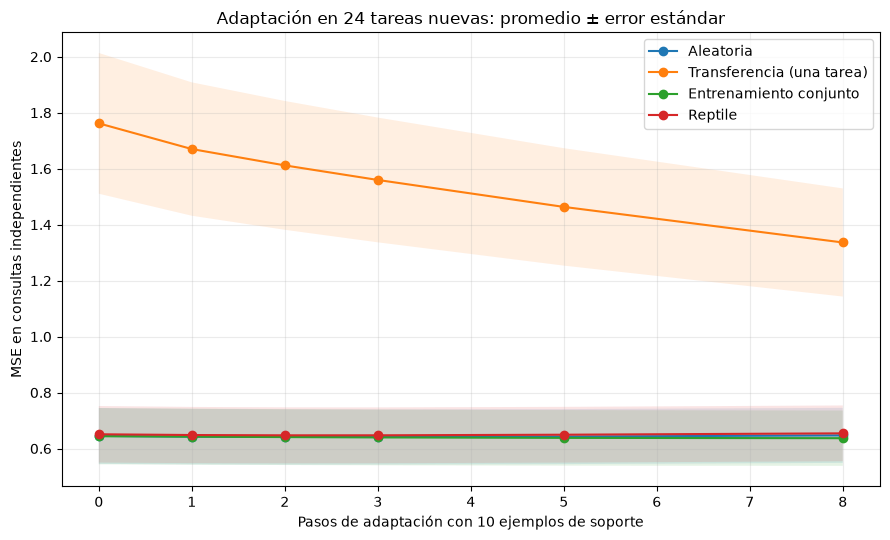

In [7]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for name, values in results.items():
    mean = values.mean(axis=0)
    sem = values.std(axis=0, ddof=1) / np.sqrt(len(values))
    ax.plot(steps_grid, mean, marker='o', label=name)
    ax.fill_between(steps_grid, mean-sem, mean+sem, alpha=0.12)
ax.set(xlabel='Pasos de adaptación con 10 ejemplos de soporte',
       ylabel='MSE en consultas independientes',
       title='Adaptación en 24 tareas nuevas: promedio ± error estándar')
ax.grid(alpha=0.25); ax.legend(); plt.tight_layout(); plt.show()


## <span style="color:#bd232b">5.3 Comparaciones pareadas, no solo curvas promedio</span>

Aleatoria                    diferencia media (otro - Reptile): -0.0073; Reptile mejora en 8/24 tareas
Transferencia (una tarea)    diferencia media (otro - Reptile): +0.6820; Reptile mejora en 18/24 tareas
Entrenamiento conjunto       diferencia media (otro - Reptile): -0.0174; Reptile mejora en 9/24 tareas


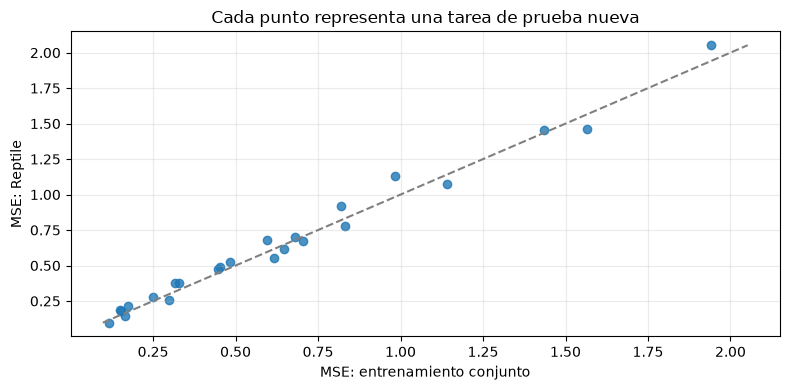

In [8]:
ref = results['Reptile'][:, -1]
for name, values in results.items():
    if name == 'Reptile':
        continue
    diff = values[:, -1] - ref   # positivo: Reptile menor error
    print(f'{name:28s} diferencia media (otro - Reptile): {diff.mean():+.4f}; '
          f'Reptile mejora en {(diff > 0).sum()}/{len(diff)} tareas')

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(results['Entrenamiento conjunto'][:, -1], ref, alpha=0.8)
lo = min(ref.min(), results['Entrenamiento conjunto'][:, -1].min())
hi = max(ref.max(), results['Entrenamiento conjunto'][:, -1].max())
ax.plot([lo,hi], [lo,hi], '--', color='gray')
ax.set(xlabel='MSE: entrenamiento conjunto', ylabel='MSE: Reptile',
       title='Cada punto representa una tarea de prueba nueva')
ax.grid(alpha=0.25); plt.tight_layout(); plt.show()


**Interpretación crítica obligatoria.** Una curva que desciende más rápidamente evidencia adaptación en este problema reducido. No demuestra superioridad general del método ni que funcionará en control industrial. Si el preentrenamiento conjunto iguala o supera a Reptile, **ese resultado también es válido**: puede indicar que el problema elegido no exige una inicialización metaaprendida o que los hiperparámetros necesitan una comparación mejor controlada.

**Precaución:** el error de consulta se calcula sobre tareas nunca utilizadas en el metaentrenamiento. No seleccionar el mejor método mirando repetidamente estas tareas y luego presentarlas como prueba final.

# <span style="color:#174ea6">6. De la regresión de tareas al control de Hydro-Lab</span>

## <span style="color:#bd232b">6.1 Correspondencia conceptual</span>

En Hydro-Lab, una tarea podría ser un episodio definido por condiciones operativas como

$$\tau=(\text{perfil de demanda},\ \text{viscosidad},\ \text{capacidad},\ \text{condición de equipos}).$$

La política continua, por ejemplo una política PPO, recibe observaciones del entorno y emite acciones sobre las bombas. La adaptación de parámetros del controlador debería evaluarse bajo **las mismas restricciones físicas** y con escenarios de prueba no utilizados en el entrenamiento.

**No debe confundirse** el laboratorio sinusoidal con una implementación de meta-RL sobre Hydro-Lab. Para eso habría que definir la distribución de tareas del simulador, un protocolo de adaptación de políticas y presupuestos comparables de interacción.

## <span style="color:#bd232b">6.2 Protocolo propuesto, sin modificar Hydro-Lab</span>

<img src="../Imagenes/arquitectura_laboratorio_G2.4.png" width="900"/>

1. **Definir tareas:** seleccionar familias de escenarios que cambien demanda, viscosidad, capacidad y condiciones operativas, si el simulador las expone y documenta.
2. **Separar por identidad de tarea:** tareas de metaentrenamiento, validación y prueba; reservar semillas nuevas para cada fase.
3. **Establecer presupuestos:** igual número de episodios, transiciones y pasos de adaptación para cada método, o declarar claramente cualquier diferencia.
4. **Medir aprendizaje y operación:** recompensa, demanda servida, energía, restricciones violadas, desgaste y terminaciones anticipadas.
5. **Contrastar:** política sin adaptación, fine-tuning convencional, inicialización metaaprendida y reglas/controles disponibles.
6. **No usar información privilegiada:** observaciones y recompensas autorizadas para el agente; cualquier variable de verdad de evaluación debe quedar fuera de la política.

La aplicación a Hydro-Lab es **una propuesta experimental**, no un resultado de ejecución. Una meta-inicialización de PPO requeriría un experimento adicional, con su propio control de versiones y validación.

# <span style="color:#174ea6">7. Actividades, discusión y cierre</span>

**Actividad 1 (clase).** Interpreta las curvas: ¿qué método parte mejor?, ¿cuál mejora más con 3 pasos?, ¿qué ocurre después de 8? Fundamenta con las salidas del experimento, no con expectativas teóricas.

**Actividad 2 (clase).** Cambia el número de muestras de soporte de 10 a 5 y a 20. ¿Cuál es el efecto sobre la adaptación? Mantén fijos los conjuntos de consulta y documenta las semillas.

**Actividad 3 (estudio autónomo).** Cambia la distribución de amplitudes o fases *solo en las tareas de prueba* para medir robustez ante desplazamiento de distribución. No vuelvas a entrenar después de observar el resultado de prueba.

**Actividad 4 (industrial).** Propón un diseño de adaptación para Hydro-Lab que compare PPO preentrenado, PPO con fine-tuning y una meta-inicialización. Explicita restricciones duras y cómo evitarías que el proceso de adaptación genere acciones inseguras.

**Pregunta de contraste:** ¿qué se aprende una sola vez, qué debe adaptarse y qué restricciones no deberían aprenderse por ensayo y error?

# <span style="color:#174ea6">8. Referencias y licencia</span>

**Referencias fundamentales**

- Finn, C., Abbeel, P. y Levine, S. (2017). *Model-Agnostic Meta-Learning for Fast Adaptation of Deep Networks*. ICML.
- Nichol, A., Achiam, J. y Schulman, J. (2018). *On First-Order Meta-Learning Algorithms*. arXiv:1803.02999.
- Sutton, R. S. y Barto, A. G. (2018). *Reinforcement Learning: An Introduction*, segunda edición.
- Documentación del proyecto **Hydro-Lab S2.11** y figura de arquitectura G2.4 (material del curso).
- Colección docente de Aprendizaje Profundo: cuadernos **103** y **104** (antecedentes de gradientes de política y PPO).

**Licencia MIT:** los textos, ejemplos y código originales de esta edición se ofrecen bajo licencia MIT, conforme al archivo `LICENSE_Cuadernos_Curso.txt` del repositorio. Las imágenes, logotipos y materiales de terceros conservan sus derechos y licencias originales; la licencia MIT no los relicencia automáticamente.

**Autores:** Alvaro Montenegro, Daniel Montenegro y Pilar Montenegro. 

**Docente:** Alvaro Montenegro. 

**Institución:** Universidad de los Andes - Ecopetrol.
